170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 697s 4us/step
Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 72s 112ms/step - accuracy: 0.4526 - loss: 1.5292 - val_accuracy: 0.4996 - val_loss: 1.4416
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 70s 112ms/step - accuracy: 0.5798 - loss: 1.1843 - val_accuracy: 0.4703 - val_loss: 1.6981
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 72s 116ms/step - accuracy: 0.6303 - loss: 1.0438 - val_accuracy: 0.6134 - val_loss: 1.0935
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 116ms/step - accuracy: 0.6651 - loss: 0.9457 - val_accuracy: 0.5597 - val_loss: 1.3725
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 117ms/step - accuracy: 0.6910 - loss: 0.8725 - val_accuracy: 0.6697 - val_loss: 0.9447
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 71s 114ms/step - accuracy: 0.7085 - loss: 0.8238 - val_accuracy: 0.5917 - val_loss: 1.2633
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 70s 112ms/step - accuracy: 0.7286 - loss: 0.7672 - val_accuracy: 0.6983 - val_loss: 0.8844
Epoch 8/10
625/625 ━━━━━━━━━

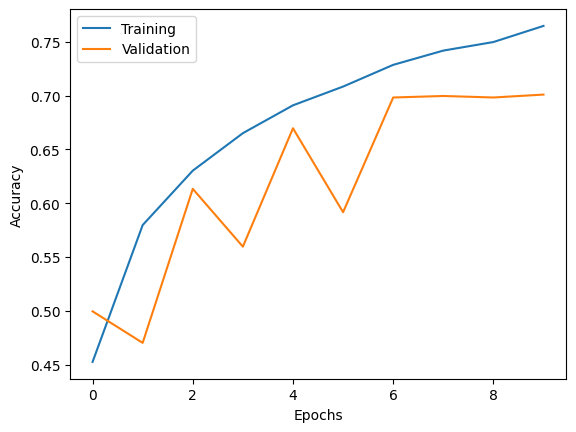

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# 2. Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Create CNN model
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# 4. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# 6. Train model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)

# 7. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100)

# 8. Plot accuracy
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
